# Day 6: Retrieval evals

Study guide: `course/week-1/day-06-retrieval-evals/README.md`

Goal: score **search on its own** (no LLM) against the golden set: recall@k (did a right chunk make the top k?) and MRR (how high was the first right chunk?).

**Setup:** reload edited `.py` files automatically.

In [1]:
%load_ext autoreload
%autoreload 2

## Steps 1–2: Metrics and the eval script
`metrics.py` (`recall_at_k`, `reciprocal_rank`, 4 tests) and `retrieval_eval.py` → `make eval-retrieval`. It searches once with k=10 per answerable question, slices for k = 1/3/5/10, and saves a dated JSON file in `evals/results/` with the **config** and per-question detail.

**First run:** recall@5 = 0.20, MRR = 0.08. Too low to believe, so look at the misses before trusting the score.

## Step 3: Fix labelling misses (honestly)
For 4 "misses", search's top result **did** answer the question; my Day 5 labels had only covered the abstract and introduction, and the papers repeat the answer in their results and conclusion. Checked each with `find_chunks` and added it only if it answers the question **on its own**: q001 ::0002, q003 ::0051, q006 ::0026, q008 ::0038.

In [2]:
from research_rag.evals.find import find_chunks

find_chunks("U-shaped", source="2307.03172.pdf")                  # q001 → is ::0002 there?
find_chunks("saturates long before", source="2307.03172.pdf")     # q003 → ::0051
find_chunks("context relevance (i.e.", source="2309.15217.pdf")   # q006 → ::0026
find_chunks("lexical variations", source="2004.04906.pdf")        # q008 → ::0038

13 chunk(s) contain 'U-shaped'
  2307.03172.pdf::0002  p.1  …ion) within the language model’s input context results in a U-shaped performance curve—models are better at using relevant information that occurs at the very beginning (primacy bias) or end…
  2307.03172.pdf::0003  p.1  …ion) within the language model’s input context results in a U-shaped performance curve—models are better at using relevant information that occurs at the very beginning (primacy bias) or end of its input contex…
  2307.03172.pdf::0006  p.2  … long input contexts. Furthermore, we observe a distinctive U-shaped performance curve (Figure 1); language model performance is highest when relevant information occurs at the very beginning (primacy bias) or …
  2307.03172.pdf::0008  p.2  …the middle of their input context and continue to exhibit a U-shaped performance curve. To better understand why language models struggle to robustly access and use information in their input contexts, we study…
  2307.03172.pdf::000

**After fixing labels (system unchanged):** recall@1 0.30 · recall@3 0.50 · recall@5 **0.50** · recall@10 0.60 · MRR **0.39**. The score went up 5× only because the answer key improved: always audit misses before trusting a number.

## Step 4: Failure analysis
What search returned for the remaining misses:

In [3]:
from research_rag.retrieval.search import search
from research_rag.evals.dataset import load_golden

MISSES = ["q002", "q004", "q005", "q007", "q009", "q010"]

for item in load_golden():
    if item.id not in MISSES:
        continue
    print(f"=== {item.id} ({item.type}): {item.question}")
    print(f"    expected: {item.relevant_chunk_ids}")
    for rank, result in enumerate(search(item.question, k=3), start=1):
        snippet = result.text[:120].replace("\n", " ")
        print(f"    #{rank} {result.similarity:.3f} {result.id}  {snippet}...")
    print()

/Users/ashutoshraichurkar/Documents/repos/research-rag/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1125 00:33:28.228000 22346 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


=== q002 (factual): Which two tasks does the Lost in the Middle paper use to study how models use long contexts?
    expected: ['2307.03172.pdf::0000']


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 10084.11it/s]


    #1 0.598 2307.03172.pdf::0066  models use? In Proc. of ACL. Dimitris Papailiopoulos, Kangwook Lee, and Jyyong Sohn. 2023. A little retrieval test for l...
    #2 0.590 2307.03172.pdf::0067  0. How context affects language models’ factual predictions. In Proc. of AKBC. Michael Poli, Stefano Massaroli, Eric Ngu...
    #3 0.574 2307.03172.pdf::0000  Lost in the Middle: How Language Models Use Long Contexts Nelson F. Liu1∗ Kevin Lin2 John Hewitt1 Ashwin Paranjape3 Mich...

=== q004 (exact_term): What does RAGAS stand for, and what is it for?
    expected: ['2309.15217.pdf::0000']
    #1 0.403 2005.11401.pdf::0042  VER is a classification task, both RAG models are equivalent. Model NQ TQA WQ CT Jeopardy-QGen MSMarco FVR-3 FVR-2 Exact...
    #2 0.358 2309.15217.pdf::0012  grounded in the given context. This is important to avoid hallucinations, and to ensure that the retrieved context can a...
    #3 0.345 2005.11401.pdf::0045  can affect performance and runtime. Figure 3 (left) shows th

## Failure analysis
- **q002 (#3):** the LitM **reference list** (p.12) took #1 and #2. → junk chunk (references)
- **q004 (miss):** a RAG-paper **results table** (::0042) is #1 for "What does RAGAS stand for?"; the answer chunk (::0000) is mostly title and author names. → acronym + junk + title chunk
- **q005 (#9):** RAGAS **results/conclusion** chunks beat the method section (::0013–0015). → wrong section
- **q007 (miss):** other DPR **tables of numbers** beat the "65.2% vs 42.9%" sentence. → exact number + junk (tables)
- **q009 (miss):** HyDE **formula** chunks (p.4) and the conclusion; the abstract starts with the title and authors. → acronym + junk (formulas) + title chunk
- **q010 (miss):** the RAG results table again, plus the Discussion (::0051 mentions "parametric and non-parametric memory" but not what each one is, so it can't answer alone and stays a miss). → junk (table) + wrong section
- **Main pattern:** junk chunks (tables, references, formulas) in 5 of 6 misses; then acronyms and exact numbers (q004, q007, q009), embeddings' blind spot.
- **Good sign:** the right *paper* is at #1 for 9/10 questions. Search gets the topic right and the chunk wrong.

## Step 5: Choosing k
Recall for every k from 1 to 10, computed from the saved top-10 IDs (no new searches):

Matplotlib is building the font cache; this may take a moment.


recall@1  0.30
recall@2  0.40
recall@3  0.50
recall@4  0.50
recall@5  0.50
recall@6  0.50
recall@7  0.50
recall@8  0.50
recall@9  0.60
recall@10 0.60


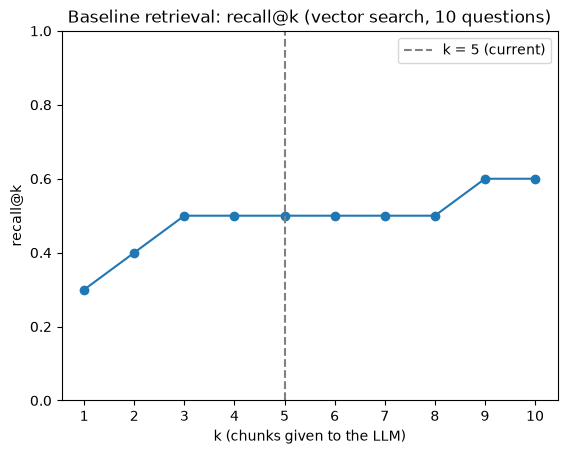

In [7]:
import json

import matplotlib.pyplot as plt

from research_rag.evals.metrics import recall_at_k
from research_rag.evals.retrieval_eval import RESULTS_DIR

report = json.loads((RESULTS_DIR / "2026-11-25_retrieval.json").read_text())

k_values = list(range(1, 11))
recalls = []
for k in k_values:
    scores = []
    for question in report["questions"]:
        scores.append(recall_at_k(question["retrieved_chunk_ids"], question["relevant_chunk_ids"], k))
    recalls.append(sum(scores) / len(scores))

for k, value in zip(k_values, recalls):
    print(f"recall@{k:<2} {value:.2f}")

plt.plot(k_values, recalls, marker="o")
plt.axvline(5, linestyle="--", color="gray", label="k = 5 (current)")
plt.xlabel("k (chunks given to the LLM)")
plt.ylabel("recall@k")
plt.title("Baseline retrieval: recall@k (vector search, 10 questions)")
plt.xticks(k_values)
plt.ylim(0, 1)
plt.legend()
plt.show()

## Choosing k
The curve is 0.30 → 0.40 → **0.50 at k=3**, flat until k=8, then 0.60 at k=9 (q005's chunk was at #9). **Keep k = 5:** it's on the plateau with margin; k=9 would nearly double the context for 1 question, and *Lost in the Middle* shows more chunks ≠ better answers. The line tops out at 0.60, so **40% of answers aren't in the top 10 at all** → fix retrieval (junk chunks, hybrid search), not k.

## Findings
- **Baseline (vector search, MiniLM, 200/40 chunks, 10 answerable questions): recall@5 = 0.50, MRR = 0.39.**
- **Main failure pattern:** junk chunks (tables, references, formulas) crowding out real text, plus acronyms and exact numbers that embeddings miss.
- **Labels can be wrong:** 4 of 8 first-run misses were labelling misses, not system errors.
- **Next:** Day 7 scores the *answers* (faithfulness, refusals) and tries removing junk chunks; Day 8 adds keyword search for the acronyms and numbers. Then re-run this notebook and compare.